# 03 · Graph neural networks and historical temporal learning
## Temporal Graph Neural Networks for Risk Detection Under Distribution Shift

Compare **GraphSAGE**, **GAT**, and **GraphSAGE + Historical GRU Context** with the saved LightGBM benchmarks under matching **18-, 93-, and 165-feature** configurations. The conservative 18-feature comparison is especially important, but **none of these inputs is certified leakage-free**.

The original dataset has no released cross-time transaction edges. Transactions do not persist across snapshots. Our temporal model summarizes earlier graphs; it never invents transaction histories or cross-time edges. Unknown-label nodes remain eligible feature/structure context but never supervised negatives.

Train neural parameters on **1–29**, choose hyperparameters and stopping epochs on **30–31**, fit only probability calibration/thresholds on **32–33**, and assess on **34** without further tuning. No test-period graph, probability, metric or ranking is constructed for **35–49**.

The first notebook's source audit remains binding: published local features include address history, and all-feature LightGBM already uses engineered graph-derived information. Matching it does not establish incremental graph-learning value. This notebook reports validation behavior, not final-test or deployment findings.

## 1. Editable architecture and experiment settings

The defaults use two graph layers and one modest two-point learning-rate grid. FULL_RUN trains three independent seeds for all nine main architecture/input combinations; seed 42 selects a common configuration, then seeds 43 and 44 independently fit that configuration with their own validation stopping epochs. We report all seeds, not a favorable seed. Controls use predefined seed 42 and the original GraphSAGE configuration without a new hyperparameter search.

QUICK_RUN retains all snapshots/nodes but uses one seed, one candidate and five epochs. It is explicitly exploratory and writes separate outputs. Architecture settings and budgets can be changed below; the two short shared graph helpers are reused for tests and checkpoint reconstruction rather than an experiment framework.

In [1]:
from pathlib import Path
import os, sys, json, time, hashlib, platform, inspect, importlib.metadata
ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src" / "data.py").is_file():
    raise RuntimeError("Launch Jupyter from the repository root or notebooks/.")
sys.path.insert(0, str(ROOT))
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache" / "matplotlib"))

RUN_MODE = "FULL_RUN"  # QUICK_RUN is exploratory, not final research evidence.
if RUN_MODE not in {"FULL_RUN", "QUICK_RUN"}:
    raise ValueError("Choose FULL_RUN or QUICK_RUN")
QUICK_RUN = RUN_MODE == "QUICK_RUN"
SEEDS = [42] if QUICK_RUN else [42, 43, 44]
PRIMARY_SEED = 42
HIDDEN_DIM = 64
CONTEXT_DIM = 32
DROPOUT = 0.25
GAT_HEADS = 2  # First layer; second attention layer uses one head.
ATTENTION_DROPOUT = 0.1
LEARNING_RATES = [0.003] if QUICK_RUN else [0.003, 0.001]
MAX_EPOCHS = 5 if QUICK_RUN else 60
PATIENCE = 3 if QUICK_RUN else 10
MIN_AP_IMPROVEMENT = 1e-4
WEIGHT_DECAY = 1e-4
GRADIENT_CLIP = 5.0
CLASS_WEIGHTED = True
CPU_THREADS = 2
TARGET_FPR = 0.01
REVIEW_K = 25
REWIRE_SEED = 2026
# "measured" prefers validated MPS if within 10% of CPU wall time; otherwise uses CPU explicitly.
# "prefer_mps" uses every validated MPS model; "cpu" requests CPU for all fits.
DEVICE_POLICY = "measured"
EMBEDDING_SAMPLE_PER_CLASS = 150
PCA_TRAIN_SAMPLE = 2000
GROUP_KEYS = {"conservative18": "transaction_sensitivity", "local93": "local_without_time",
              "published165": "published_without_time"}
ARCHITECTURES = ["graphsage", "gat", "sage_gru"]
NAMES = {"graphsage": "GraphSAGE", "gat": "GAT", "sage_gru": "GraphSAGE + Historical GRU Context",
         "lightgbm": "LightGBM"}
GROUP_NAMES = {"conservative18": "Transaction 18", "local93": "Local 93", "published165": "Published 165"}
MODE_FOLDER = "quick_run" if QUICK_RUN else "full_run"
RESULT_DIR = ROOT / "results" / "stage3" / MODE_FOLDER
PRIVATE_DIR = ROOT / "results" / "local" / "stage3" / MODE_FOLDER
MODEL_DIR = ROOT / "models" / "stage3" / MODE_FOLDER
FIGURE_DIR = ROOT / "reports" / "figures"
if QUICK_RUN:
    FIGURE_DIR = FIGURE_DIR / "exploratory_stage3"
for directory in [RESULT_DIR, PRIVATE_DIR, MODEL_DIR, FIGURE_DIR, RESULT_DIR / "histories"]:
    directory.mkdir(parents=True, exist_ok=True)
DATA_DIR = Path(os.environ.get("ELLIPTIC_DATA_DIR", "data/raw"))
if not DATA_DIR.is_absolute():
    DATA_DIR = ROOT / DATA_DIR
started_at = time.perf_counter()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from torch_geometric.data import Batch
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import average_precision_score, precision_recall_curve
from sklearn.decomposition import PCA
from scipy.special import expit
import joblib
from IPython.display import display, Markdown, Code

from src.data import load_elliptic, feature_groups, file_fingerprints
from src.baselines import development_frames, fit_sigmoid_calibrator, apply_sigmoid
from src.evaluation import (prediction_frame, assert_common_population, evaluate_predictions,
                            choose_thresholds, PREDICTION_COLUMNS)
from src.graph_learning import (SnapshotEncoder, GraphRiskModel, build_snapshots,
                               training_targets, fit_loss, infer_snapshots)
from src.graph_hardware import seed_everything, probe_graph_devices, benchmark_backends

torch.set_num_threads(CPU_THREADS)
seed_everything(PRIMARY_SEED)
FEATURE_SETS = {name: feature_groups()[key] for name, key in GROUP_KEYS.items()}
COLORS = {"graphsage": "#0072B2", "gat": "#E69F00", "sage_gru": "#009E73", "lightgbm": "#CC79A7"}
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "svg.fonttype": "none",
                     "axes.spines.top": False, "axes.spines.right": False})
figure_names = []

def save_figure(figure, name):
    figure.tight_layout()
    figure.savefig(FIGURE_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    figure.savefig(FIGURE_DIR / f"{name}.svg", bbox_inches="tight")
    figure_names.append(name)
    plt.show()
    plt.close(figure)

print(f"{RUN_MODE}; exploratory={QUICK_RUN}; seeds={SEEDS}; epochs≤{MAX_EPOCHS}")

FULL_RUN; exploratory=False; seeds=[42, 43, 44]; epochs≤60


## 2. Development data and matched tabular information

The loader verifies the original release, then graph construction is hard-limited to steps 1–34. Only steps 1–29 can enter the optimizer loss. We verify the Stage 1 hashes and use exactly the Stage 2 feature order and labeled validation populations. Scalers fit the same **known training rows** as the LR baseline, then transform eligible known/unknown graph nodes. No validation features fit preprocessing.

The LightGBM feature-gain statistic below reproduces the review's address-history share from the saved training importance table. Gain is not a causal estimate of contamination or an explanation of generalization.

In [2]:
nodes, edges, diagnostics = load_elliptic(DATA_DIR)
raw_hashes = file_fingerprints(DATA_DIR)
manifest = json.loads((ROOT / "data" / "processed" / "split_manifest.json").read_text())
if raw_hashes != manifest["raw_sha256"]:
    raise ValueError("Raw inputs differ from Stage 1 memberships")
baseline_dir = ROOT / "results" / "stage2" / "full_run"
baseline_config = json.loads((baseline_dir / "selected_configurations.json").read_text())
if baseline_config["raw_sha256"] != raw_hashes:
    raise ValueError("Stage 2 inputs differ")
for group, columns in FEATURE_SETS.items():
    assert columns == baseline_config["feature_sets"][group]
frames = development_frames(nodes)
train_rows, selection_rows = frames["train"], frames["selection"]
calibration_rows, audit_rows = frames["calibration"], frames["audit"]
validation_rows = pd.concat([selection_rows, calibration_rows, audit_rows]).sort_values("tx_id")
assert set(train_rows.node_index).isdisjoint(validation_rows.node_index)
positive_weight = float((train_rows.target == 0).sum() / train_rows.target.sum()) if CLASS_WEIGHTED else 1.0
scalers, original_graphs = {}, {}
for group, key in GROUP_KEYS.items():
    scaler = StandardScaler().fit(train_rows[FEATURE_SETS[group]])
    scalers[group] = scaler
    joblib.dump(scaler, MODEL_DIR / f"scaler__{group}.joblib")
    original_graphs[group] = build_snapshots(nodes, edges, scaler, key, max_step=34)
    assert all("y" not in graph and "target" not in graph for graph in original_graphs[group].values())

graph_counts = pd.DataFrame([
    {"time_step": step, "nodes": graph.num_nodes, "known_labels": int(nodes.iloc[graph.node_index.numpy()].target.notna().sum()),
     "directed_edges": graph.num_edges} for step, graph in original_graphs["conservative18"].items()
])
graph_counts.to_csv(RESULT_DIR / "snapshot_counts.csv", index=False)
display(pd.DataFrame([{"role": name, "known_labels": len(rows), "illicit": int(rows.target.sum()),
                      "steps": f"{rows.time_step.min()}–{rows.time_step.max()}"} for name, rows in frames.items()]))
display(pd.DataFrame([{"configuration": group, "features": len(columns), "certified_leakage_free": False}
                      for group, columns in FEATURE_SETS.items()]))
importance = pd.read_csv(baseline_dir / "lightgbm_gain_importance.csv")
feature_numbers = importance.feature.str.extract(r"(\d+)")[0].astype(int)
address_gain_share = float(importance.loc[feature_numbers.between(23, 94), "gain_fraction"].sum())
print(f"Stage 2 selected Published-165 LightGBM: {address_gain_share:.1%} of gain in address-history features 23–94.")

,role,known_labels,illicit,steps
0,train,26381,2871,1–29
1,selection,1234,189,30–31
2,calibration,1764,365,32–33
3,audit,515,37,34–34


,configuration,features,certified_leakage_free
0,conservative18,18,False
1,local93,93,False
2,published165,165,False


Stage 2 selected Published-165 LightGBM: 63.6% of gain in address-history features 23–94.


## 3. Direction, masking and the temporal model

PyG's `source_to_target` convention reads `edge_index[0]` as sender and `edge_index[1]` as receiver. A released payment edge $u\to v$ therefore sends $u$'s information into $v$. We preserve that direction. GAT adds within-snapshot self loops internally; GraphSAGE has its root-feature term. Neither creates a cross-snapshot edge.

For the temporal model, $z_{i,t}$ is the current GraphSAGE node embedding, $s_t=|V_t|^{-1}\sum_i z_{i,t}$ pools **all observed nodes**, and

$$\ell_{i,t}=w^\top[z_{i,t},h_{t-1}]+b,\qquad h_t=\mathrm{GRUCell}(s_t,h_{t-1}).$$

The classifier uses $h_{t-1}$ before the current summary updates the state. Unknown nodes contribute features to eligible graph messages and summaries because those transactions are observed at snapshot end. They never contribute a supervised label. The GRU receives no target, ID, validation label or fictional per-node history.

Full backpropagation through training snapshots 1–29 learns the encoder, GRU and head jointly. State resets every epoch. During frozen inference, earlier validation graphs may update **feature-only** history after their prediction; labels cannot update neural parameters. This is chronological new-snapshot inference, not proof of generalization to unseen entities hidden by the release.

The model definitions are short and shown below; architectural widths, dropout, heads and context size are editable in Section 1. The helper location also allows tests and later notebooks to reconstruct saved state dictionaries without copying model code.

**Scope of this temporal extension:** the linear concatenation head makes historical context a shared snapshot-level logit offset. It can adapt probabilities to between-snapshot conditions, but cannot directly change within-snapshot node ranking at fixed encoder/head weights. Static-versus-temporal AP differences therefore reflect joint training and different parameterizations; they do not isolate a benefit from history. A nonlinear interaction head and a capacity-matched static control would require a separately declared experiment, not tuning after step 34.

In [3]:
display(Code(inspect.getsource(SnapshotEncoder) + "\n\n" + inspect.getsource(GraphRiskModel), language="python"))
# Static full-batch training joins disjoint snapshots for efficiency, not message passing between them.
training_graphs_cpu = {step: original_graphs["conservative18"][step] for step in range(1, 30)}
training_batch_check = Batch.from_data_list(list(training_graphs_cpu.values()))
source, target = training_batch_check.edge_index
assert torch.equal(training_batch_check.batch[source], training_batch_check.batch[target])
print("No cross-graph messages in the static training batch; unknown targets remain outside graph objects.")

class SnapshotEncoder(nn.Module):
    """Two graph layers; normalization is within each node, never across time."""

    def __init__(self, input_dim, hidden_dim, dropout, architecture, heads=2, attention_dropout=0.1):
        super().__init__()
        if architecture == "gat":
            if hidden_dim % heads:
                raise ValueError("hidden_dim must be divisible by GAT heads")
            self.first = GATConv(input_dim, hidden_dim // heads, heads=heads,
                                 dropout=attention_dropout, add_self_loops=True, flow="source_to_target")
            self.second = GATConv(hidden_dim, hidden_dim, heads=1, concat=False,
                                  dropout=attention_dropout, add_self_loops=True, flow="source_to_target")
        else:
            self.first = SAGEConv(input_dim, hidden_dim, aggr="mean", flow="source_to_target")
            self.second = SAGEConv(hidden_dim, hidden_dim, aggr="mean", flow="source_to_target")
        self.norm_first = nn.LayerNorm(hidden_dim)
        self.norm_second = nn.LayerNorm(hidden_dim)
        self.dropout = dropout

    def forward(self, x, edge_index):
        x = F.relu(self.norm_first(self.first(x, edge_index)))
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = F.relu(self.norm_second(self.second(x, edge_index)))
        return F.dropout(x, p=self.dropout, training=self.training)


class GraphRiskModel(nn.Module):
    """GraphSAGE, GAT, or GraphSAGE + Historical GRU Context; no node memory."""

    def __init__(self, input_dim, architecture="graphsage", hidden_dim=64, dropout=0.25,
                 heads=2, context_dim=32, attention_dropout=0.1):
        super().__init__()
        if architecture not in ("graphsage", "gat", "sage_gru"):
            raise ValueError("Unknown architecture")
        self.temporal = architecture == "sage_gru"
        self.context_dim = context_dim
        self.encoder = SnapshotEncoder(input_dim, hidden_dim, dropout, architecture, heads, attention_dropout)
        if self.temporal:
            self.gru = nn.GRUCell(hidden_dim, context_dim)
        self.classifier = nn.Linear(hidden_dim + (context_dim if self.temporal else 0), 1)

    def forward(self, graph, context=None):
        embeddings = self.encoder(graph.x, graph.edge_index)
        if self.temporal:
            if context is None:
                context = embeddings.new_zeros((1, self.context_dim))
            combined = torch.cat([embeddings, context.expand(len(embeddings), -1)], dim=1)
            logits = self.classifier(combined).squeeze(-1)
            # Prediction precedes the update: current summary can influence t+1 only.
            next_context = self.gru(embeddings.mean(dim=0, keepdim=True), context)
        else:
            logits = self.classifier(embeddings).squeeze(-1)
            next_context = None
        return logits, next_context, embeddings

No cross-graph messages in the static training batch; unknown targets remain outside graph objects.


## 4. Apple Silicon operation checks and backend choice

Every architecture is compared on CPU/MPS using actual scaled training snapshots: logits, parameter gradients, an Adam update, dropout and masked BCE must be finite and within declared tolerances. The temporal probe exercises GraphSAGE, mean pooling and GRUCell together. Implicit MPS fallback is never accepted.

A short warm timing check then compares the full optimizer-plus-feature-only-selection workload. With `measured`, a validated MPS model is used if its measured time is within 10% of CPU; otherwise CPU is chosen explicitly to avoid small-graph dispatch overhead. This is a runtime decision, never an accuracy choice. Use `prefer_mps` to request every passing MPS model. Sparse extensions and unrelated PyG operations are not certified by these tests.

In [4]:
model_options = {"input_dim": 165, "hidden_dim": HIDDEN_DIM, "dropout": DROPOUT, "heads": GAT_HEADS,
                 "context_dim": CONTEXT_DIM, "attention_dropout": ATTENTION_DROPOUT}
probe_graphs = original_graphs["published165"]
hardware_report = probe_graph_devices(model_options, [probe_graphs[28], probe_graphs[29]])
probe_targets = training_targets(nodes, {step: probe_graphs[step] for step in range(1, 30)})
backend_timings = benchmark_backends(model_options, probe_graphs, probe_targets, positive_weight, hardware_report)
timing_table = pd.DataFrame(backend_timings)
BACKENDS, backend_reasons = {}, {}
if DEVICE_POLICY not in {"measured", "prefer_mps", "cpu"}:
    raise ValueError("Unknown device policy")
for architecture in ARCHITECTURES:
    verified = hardware_report["devices"][architecture]
    chosen = verified
    reason = "Verified MPS" if verified == "mps" else "MPS unavailable or failed parity; use CPU"
    if DEVICE_POLICY == "cpu":
        chosen, reason = "cpu", "Explicit CPU request"
    elif DEVICE_POLICY == "measured" and verified == "mps":
        timings = timing_table.loc[timing_table.architecture == architecture].set_index("device")
        if timings.loc["mps", "seconds_per_epoch"] > 1.1 * timings.loc["cpu", "seconds_per_epoch"]:
            chosen, reason = "cpu", "CPU faster on the measured snapshot workload"
    BACKENDS[architecture], backend_reasons[architecture] = chosen, reason
hardware_report.update(chosen_backends=BACKENDS, backend_reasons=backend_reasons,
                       policy=DEVICE_POLICY, timing_measurements=backend_timings,
                       parity_tolerances={"logits_rtol": 0.002, "logits_atol": 0.0002,
                                          "gradients_rtol": 0.003, "gradients_atol": 0.00005})
(RESULT_DIR / "hardware_validation.json").write_text(json.dumps(hardware_report, indent=2) + "\n")
display(pd.DataFrame(hardware_report["checks"]))
display(timing_table)
display(pd.DataFrame({"backend": BACKENDS, "reason": backend_reasons}))

,architecture,device,status,seconds
0,graphsage,cpu,passed,0.0177
1,graphsage,mps,passed,0.2771
2,gat,cpu,passed,0.0322
3,gat,mps,passed,0.2094
4,sage_gru,cpu,passed,0.0216
5,sage_gru,mps,passed,0.0992


,architecture,device,seconds_per_epoch,timed_epochs
0,graphsage,cpu,0.157832,2
1,graphsage,mps,0.070392,2
2,gat,cpu,0.239914,2
3,gat,mps,0.126751,2
4,sage_gru,cpu,0.298088,2
5,sage_gru,mps,0.365761,2


,backend,reason
graphsage,mps,Verified MPS
gat,mps,Verified MPS
sage_gru,cpu,CPU faster on the measured snapshot workload


## 5. Explicit training, validation and early stopping

Each epoch takes one optimizer step on the full labeled training objective. Static models batch disjoint training graphs; temporal training performs an ordered 29-snapshot pass with full gradients through earlier summaries. Positive weighting uses training labels only. Validation AP on 30–31 chooses checkpoints and candidates. Loss curves use the same training-derived positive weighting on both populations; their levels also reflect different labeled prevalences.

Training stops after the configured patience without AP improvement of at least `MIN_AP_IMPROVEMENT`. No optimizer step uses a validation graph or label. Numerical errors abort the fit. An unsupported MPS runtime error discards that attempt and restarts the whole fit from its initial seed on CPU, with the event recorded.

In [5]:
fit_records = []

def graphs_for(group, edge_mode="original"):
    if edge_mode == "original":
        return original_graphs[group]
    return build_snapshots(nodes, edges, scalers[group], GROUP_KEYS[group], edge_mode=edge_mode,
                           max_step=34, rewire_seed=REWIRE_SEED)

def model_configuration(architecture, group):
    return {"input_dim": len(FEATURE_SETS[group]), "architecture": architecture,
            "hidden_dim": HIDDEN_DIM, "dropout": DROPOUT, "heads": GAT_HEADS,
            "context_dim": CONTEXT_DIM, "attention_dropout": ATTENTION_DROPOUT}

def known_outputs(outputs, graphs, steps):
    row_parts, scores = [], []
    for step in steps:
        rows = nodes.iloc[graphs[step].node_index.cpu().numpy()]
        known = rows.target.notna().to_numpy()
        row_parts.append(rows.loc[known])
        scores.append(outputs[step]["logits"][known])
    return pd.concat(row_parts), np.concatenate(scores)

def training_attempt(architecture, group, edge_mode, seed, learning_rate, run_id, device):
    run_started = time.perf_counter()
    seed_everything(seed)
    config = model_configuration(architecture, group)
    model = GraphRiskModel(**config).to(device)
    initial_hash = hashlib.sha256(b"".join(p.detach().cpu().numpy().tobytes() for p in model.parameters())).hexdigest()
    cpu_graphs = graphs_for(group, edge_mode)
    graphs = {step: graph.clone().to(device) for step, graph in cpu_graphs.items()}
    train_graphs = {step: graphs[step] for step in range(1, 30)}
    targets_cpu = training_targets(nodes, {step: cpu_graphs[step] for step in range(1, 30)})
    targets = {step: values.to(device) for step, values in targets_cpu.items()}
    batch = Batch.from_data_list(list(train_graphs.values())) if not model.temporal else None
    weight = torch.tensor(positive_weight, dtype=torch.float32, device=device)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=WEIGHT_DECAY)
    history, best_state = [], None
    best_ap, wait, best_epoch = -np.inf, 0, 0
    training_seconds = selection_seconds = 0.0
    for epoch in range(1, MAX_EPOCHS + 1):
        epoch_started = time.perf_counter()
        model.train()
        optimizer.zero_grad(set_to_none=True)
        loss = fit_loss(model, train_graphs, targets, weight, batch)
        if not torch.isfinite(loss):
            raise FloatingPointError("Nonfinite training loss; no checkpoint accepted")
        loss.backward()
        gradient_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP, error_if_nonfinite=True)
        optimizer.step()
        if not all(torch.isfinite(parameter).all().item() for parameter in model.parameters()):
            raise FloatingPointError("Nonfinite parameters after optimizer update")
        training_seconds += time.perf_counter() - epoch_started
        selection_started = time.perf_counter()
        outputs = infer_snapshots(model, graphs, [30, 31])
        rows, scores = known_outputs(outputs, cpu_graphs, [30, 31])
        labels = rows.target.to_numpy(dtype=np.float32)
        selection_ap = average_precision_score(labels, expit(scores))
        selection_loss = float(nn.functional.binary_cross_entropy_with_logits(
            torch.from_numpy(scores), torch.from_numpy(labels), pos_weight=torch.tensor(positive_weight)))
        selection_seconds += time.perf_counter() - selection_started
        history.append({"epoch": epoch, "training_loss": float(loss.detach().cpu()),
                        "selection_loss": selection_loss, "selection_ap": float(selection_ap),
                        "gradient_norm_before_clip": float(gradient_norm.detach().cpu())})
        if selection_ap > best_ap + MIN_AP_IMPROVEMENT:
            best_ap, best_epoch, wait = float(selection_ap), epoch, 0
            best_state = {name: value.detach().cpu().clone() for name, value in model.state_dict().items()}
        else:
            wait += 1
        if wait >= PATIENCE:
            break
    if best_state is None:
        raise RuntimeError("No finite selected checkpoint")
    checkpoint = {"model_config": config, "state_dict": best_state, "seed": seed,
        "train_steps": list(range(1, 30)), "selection_steps": [30, 31], "best_epoch": best_epoch,
        "selection_ap": best_ap, "learning_rate": learning_rate, "positive_weight": positive_weight,
        "weight_decay": WEIGHT_DECAY, "gradient_clip": GRADIENT_CLIP, "edge_mode": edge_mode,
        "feature_group": group, "feature_columns": FEATURE_SETS[group], "device": device,
        "initial_parameter_sha256": initial_hash, "raw_sha256": raw_hashes}
    torch.save(checkpoint, MODEL_DIR / f"{run_id}.pt")
    pd.DataFrame(history).to_csv(RESULT_DIR / "histories" / f"{run_id}.csv", index=False)
    return {"run_id": run_id, "architecture": architecture, "feature_configuration": group,
            "edge_mode": edge_mode, "seed": seed, "learning_rate": learning_rate, "device": device,
            "selection_ap": best_ap, "best_epoch": best_epoch, "epochs_run": len(history),
            "fit_seconds": time.perf_counter() - run_started, "training_seconds": training_seconds,
            "selection_seconds": selection_seconds, "parameters": sum(p.numel() for p in model.parameters()),
            "initial_parameter_sha256": initial_hash}

def fit_candidate(architecture, group, edge_mode, seed, learning_rate, suffix):
    run_id = f"{architecture}__{group}__{edge_mode}__seed{seed}__{suffix}"
    device = BACKENDS[architecture]
    attempt_started = time.perf_counter()
    try:
        result = training_attempt(architecture, group, edge_mode, seed, learning_rate, run_id, device)
        result["cpu_restart_reason"] = None
    except (RuntimeError, NotImplementedError) as error:
        message = str(error).lower()
        unsupported = any(text in message for text in ["not implemented", "not supported", "unsupported", "mps backend out of memory"])
        if device != "mps" or not unsupported:
            raise
        print(f"{run_id}: discard MPS attempt; restart the entire fit on CPU: {str(error).splitlines()[0]}")
        result = training_attempt(architecture, group, edge_mode, seed, learning_rate, run_id, "cpu")
        result["cpu_restart_reason"] = str(error).splitlines()[0]
    result["total_attempt_seconds"] = time.perf_counter() - attempt_started
    fit_records.append(result)
    pd.DataFrame(fit_records).to_csv(RESULT_DIR / "fit_progress.csv", index=False)
    print(f"{run_id}: AP(30–31)={result['selection_ap']:.4f}, epoch {result['best_epoch']}/{result['epochs_run']}, {result['device']}")
    return result

## 6. Main models: small selection grid, independent training seeds

Only seed 42 runs the small grid. Its winning configuration is then reused for the other seeds. Every independent fit resets initialization and dropout seeds; no average or best seed selects a candidate. Main results will report mean and standard deviation across training seeds, which is not a sampling-confidence interval.

In [6]:
selected_runs = []
for group in FEATURE_SETS:
    for architecture in ARCHITECTURES:
        candidates = []
        for candidate_index, learning_rate in enumerate(LEARNING_RATES):
            candidates.append(fit_candidate(architecture, group, "original", PRIMARY_SEED,
                                             learning_rate, f"candidate{candidate_index}"))
        # Exact candidate ties keep the first listed learning rate.
        selected = max(candidates, key=lambda result: result["selection_ap"])
        selected_runs.append(dict(selected, experiment="main"))
        for seed in SEEDS:
            if seed == PRIMARY_SEED:
                continue
            result = fit_candidate(architecture, group, "original", seed,
                                   selected["learning_rate"], "selected")
            selected_runs.append(dict(result, experiment="main"))
main_runs = pd.DataFrame(selected_runs)
main_runs.to_csv(RESULT_DIR / "selected_main_runs.csv", index=False)
display(main_runs[["architecture", "feature_configuration", "seed", "learning_rate", "selection_ap",
                   "best_epoch", "epochs_run", "device", "fit_seconds"]].round(4))

graphsage__conservative18__original__seed42__candidate0: AP(30–31)=0.6210, epoch 60/60, mps


graphsage__conservative18__original__seed42__candidate1: AP(30–31)=0.5632, epoch 60/60, mps


graphsage__conservative18__original__seed43__selected: AP(30–31)=0.6088, epoch 60/60, mps


graphsage__conservative18__original__seed44__selected: AP(30–31)=0.5593, epoch 25/35, mps


gat__conservative18__original__seed42__candidate0: AP(30–31)=0.3884, epoch 41/51, mps


gat__conservative18__original__seed42__candidate1: AP(30–31)=0.2528, epoch 7/17, mps


... (27 outputs left out)

sage_gru__published165__original__seed42__candidate1: AP(30–31)=0.8270, epoch 57/60, cpu


sage_gru__published165__original__seed43__selected: AP(30–31)=0.8603, epoch 33/43, cpu


sage_gru__published165__original__seed44__selected: AP(30–31)=0.8551, epoch 29/39, cpu


,architecture,feature_configuration,seed,learning_rate,selection_ap,best_epoch,epochs_run,device,fit_seconds
0,graphsage,conservative18,42,0.003,0.6210,60,60,mps,3.6314
1,graphsage,conservative18,43,0.003,0.6088,60,60,mps,3.4578
2,graphsage,conservative18,44,0.003,0.5593,25,35,mps,2.0393
3,gat,conservative18,42,0.003,0.3884,41,51,mps,7.1736
4,gat,conservative18,43,0.003,0.4412,48,58,mps,8.1304
5,gat,conservative18,44,0.003,0.3082,3,13,mps,1.8497
6,sage_gru,conservative18,42,0.003,0.5845,25,35,cpu,7.8458
7,sage_gru,conservative18,43,0.003,0.6215,59,60,cpu,14.1490
8,sage_gru,conservative18,44,0.003,0.6139,48,58,cpu,14.2254
9,graphsage,local93,42,0.003,0.8747,26,36,mps,2.7491


## 7. Graph controls and direction sensitivity

Controls retrain GraphSAGE with the original-edge configuration, same loss/budget and predefined seed 42. They use training graphs only and stopping on 30–31. **Self-only** empties the edge list, leaving root features and learned constants. **Rewired** draws a simple directed graph inside each snapshot with the exact original edge count, no duplicate edges or self loops; it does **not** preserve node degrees. The graph draw uses fixed `REWIRE_SEED + time_step`, independently of model initialization.

Rewiring is a negative control, not a realistic transaction network. Reversed-edge sensitivity is limited to the important 18- and 165-feature configurations. It changes aggregation direction within the end-of-snapshot information boundary, not the recorded transaction flow or time partition. All original graphs remain intact.

In [7]:
for group in FEATURE_SETS:
    original = next(run for run in selected_runs if run["experiment"] == "main"
                    and run["architecture"] == "graphsage" and run["feature_configuration"] == group
                    and run["seed"] == PRIMARY_SEED)
    modes = ["self_only", "rewired"]
    if group in ["conservative18", "published165"]:
        modes.append("reversed")
    for edge_mode in modes:
        result = fit_candidate("graphsage", group, edge_mode, PRIMARY_SEED, original["learning_rate"], "control")
        selected_runs.append(dict(result, experiment="control"))
selected_table = pd.DataFrame(selected_runs)
selected_table.to_csv(RESULT_DIR / "selected_runs.csv", index=False)
print(f"{len(selected_table)} selected main/control fits; {len(fit_records)} total fitted candidates.")

graphsage__conservative18__self_only__seed42__control: AP(30–31)=0.3856, epoch 3/13, mps


graphsage__conservative18__rewired__seed42__control: AP(30–31)=0.5206, epoch 32/42, mps


graphsage__conservative18__reversed__seed42__control: AP(30–31)=0.5372, epoch 20/30, mps


graphsage__local93__self_only__seed42__control: AP(30–31)=0.8185, epoch 48/58, mps


graphsage__local93__rewired__seed42__control: AP(30–31)=0.7423, epoch 56/60, mps


graphsage__published165__self_only__seed42__control: AP(30–31)=0.7055, epoch 11/21, mps


graphsage__published165__rewired__seed42__control: AP(30–31)=0.7664, epoch 60/60, mps


graphsage__published165__reversed__seed42__control: AP(30–31)=0.8785, epoch 57/60, mps
35 selected main/control fits; 44 total fitted candidates.


## 8. Frozen validation predictions, calibration and checkpoint checks

Every selected checkpoint is loaded from disk before prediction. Neural parameters remain frozen; a separate Platt-style calibrator and F1/FPR rules use 32–33 only, as in Stage 2. Raw rows cover known validation labels 30–34; calibrated rows cover 34 only. Early selection rows are reused selection scores, not independent performance estimates.

Checkpoints use state dictionaries and explicit model configurations. Calibrators/scalers stay in local joblib files. No per-node predictions, embeddings, IDs, or checkpoints are redistributed in the publication package. Probabilities use the same seven-column format as Stage 2. Reload checks use the same backend and explicit tolerances rather than claiming cross-device bitwise identity.

In [8]:
raw_frames, audit_frames, metric_records, checkpoint_checks, rule_records = [], [], [], [], []
for run in selected_runs:
    checkpoint = torch.load(MODEL_DIR / f"{run['run_id']}.pt", map_location="cpu", weights_only=True)
    model = GraphRiskModel(**checkpoint["model_config"])
    model.load_state_dict(checkpoint["state_dict"])
    device = run["device"]
    model.to(device)
    cpu_graphs = graphs_for(run["feature_configuration"], run["edge_mode"])
    device_graphs = {step: graph.clone().to(device) for step, graph in cpu_graphs.items()}
    outputs = infer_snapshots(model, device_graphs, [30, 31, 32, 33, 34])
    rows, scores = known_outputs(outputs, cpu_graphs, [30, 31, 32, 33, 34])
    model_id = f"{run['architecture']}__{run['feature_configuration']}__{run['edge_mode']}__seed{run['seed']}"
    raw = prediction_frame(rows, expit(scores), model_id + "__raw", run["seed"])
    raw_frames.append(raw)
    calibration_mask = raw.time_step.isin([32, 33]).to_numpy()
    audit_mask = raw.time_step.eq(34).to_numpy()
    calibration_predictions = raw.loc[calibration_mask].copy()
    raw_rules = choose_thresholds(calibration_predictions, TARGET_FPR)
    calibrator = fit_sigmoid_calibrator(calibration_predictions, scores[calibration_mask])
    calibrated_fit = calibration_predictions.copy()
    calibrated_fit["model_name"] = model_id + "__platt"
    calibrated_fit["predicted_probability"] = apply_sigmoid(calibrator, scores[calibration_mask])
    calibrated_rules = choose_thresholds(calibrated_fit, TARGET_FPR)
    raw_audit = raw.loc[audit_mask].copy()
    calibrated_audit = raw_audit.copy()
    calibrated_audit["model_name"] = model_id + "__platt"
    calibrated_audit["predicted_probability"] = apply_sigmoid(calibrator, scores[audit_mask])
    audit_frames.extend([raw_audit, calibrated_audit])
    for variant, frame, rules in [("raw", raw_audit, raw_rules), ("platt", calibrated_audit, calibrated_rules)]:
        metric_records.append({"model_id": model_id, "architecture": run["architecture"],
            "feature_configuration": run["feature_configuration"], "edge_mode": run["edge_mode"],
            "seed": run["seed"], "experiment": run["experiment"], "calibration": variant,
            "fit_seconds": run["fit_seconds"], "device": device, "best_epoch": run["best_epoch"],
            **evaluate_predictions(frame, rules, REVIEW_K)})
    joblib.dump({"calibrator": calibrator, "raw_thresholds": raw_rules, "calibrated_thresholds": calibrated_rules},
                MODEL_DIR / f"{run['run_id']}__calibration.joblib")
    restored = GraphRiskModel(**checkpoint["model_config"])
    restored.load_state_dict(torch.load(MODEL_DIR / f"{run['run_id']}.pt", map_location="cpu", weights_only=True)["state_dict"])
    restored.to(device)
    restored_scores = known_outputs(infer_snapshots(restored, device_graphs, [34]), cpu_graphs, [34])[1]
    np.testing.assert_allclose(restored_scores, scores[audit_mask], rtol=1e-4, atol=1e-5)
    checkpoint_checks.append({"run_id": run["run_id"], "same_backend": device,
                              "maximum_logit_reload_difference": float(np.max(np.abs(restored_scores - scores[audit_mask]))),
                              "passed": True})
    serial_rules = {}
    for name, rules in [("raw", raw_rules), ("platt", calibrated_rules)]:
        serial_rules[name] = dict(rules)
        if not np.isfinite(serial_rules[name]["fpr_threshold"]):
            serial_rules[name]["fpr_threshold"] = None  # predict none; fitted joblib retains infinity.
    rule_records.append({"model_id": model_id, "run_id": run["run_id"], "rules": serial_rules,
                         "calibration_slope": float(calibrator.coef_[0, 0]),
                         "calibration_intercept": float(calibrator.intercept_[0])})

raw_predictions = pd.concat(raw_frames, ignore_index=True)
audit_predictions = pd.concat(audit_frames, ignore_index=True)
assert_common_population(raw_predictions, validation_rows)
assert_common_population(audit_predictions, audit_rows)
raw_predictions.to_csv(PRIVATE_DIR / "validation_raw_predictions.csv", index=False)
audit_predictions.loc[audit_predictions.model_name.str.endswith("__platt")].to_csv(
    PRIVATE_DIR / "validation_calibrated_step34_predictions.csv", index=False)
metrics_table = pd.DataFrame(metric_records)
metrics_table.to_csv(RESULT_DIR / "validation_metrics.csv", index=False)
(RESULT_DIR / "checkpoint_checks.json").write_text(json.dumps(checkpoint_checks, indent=2) + "\n")
(RESULT_DIR / "operating_rules.json").write_text(json.dumps(rule_records, indent=2, allow_nan=False) + "\n")
main_raw = metrics_table.loc[(metrics_table.experiment == "main") & (metrics_table.calibration == "raw")]
aggregate = main_raw.groupby(["architecture", "feature_configuration"], sort=False).agg(
    ap_mean=("average_precision", "mean"), ap_sd=("average_precision", "std"), seeds=("seed", "count"),
    roc_auc_mean=("roc_auc", "mean"), brier_mean=("brier_score", "mean"),
    fit_seconds_mean=("fit_seconds", "mean"), fit_seconds_sd=("fit_seconds", "std")).reset_index()
aggregate.to_csv(RESULT_DIR / "main_seed_summary.csv", index=False)
display(aggregate.round(4))

,architecture,feature_configuration,ap_mean,ap_sd,seeds,roc_auc_mean,brier_mean,fit_seconds_mean,fit_seconds_sd
0,graphsage,conservative18,0.4776,0.0160,3,0.8030,0.1960,3.0428,0.8734
1,gat,conservative18,0.3063,0.0183,3,0.7304,0.2906,5.7179,3.3840
2,sage_gru,conservative18,0.5061,0.0125,3,0.8026,0.1923,12.0734,3.6614
3,graphsage,local93,0.6704,0.0573,3,0.9438,0.1112,3.1558,0.5291
4,gat,local93,0.5259,0.1214,3,0.9176,0.1755,7.6290,0.6875
5,sage_gru,local93,0.6484,0.0335,3,0.9220,0.1174,10.3277,0.8482
6,graphsage,published165,0.6966,0.0311,3,0.9555,0.1156,4.8072,0.1966
7,gat,published165,0.6342,0.0124,3,0.9313,0.1705,8.3201,0.0196
8,sage_gru,published165,0.6858,0.0265,3,0.9455,0.1366,14.6738,3.2206


**Interpretation:** All reported assessment metrics use the same step-34 labeled population. Seed SD quantifies initialization/training variability, not label-sampling uncertainty. Calibration cannot repair source-level leakage. A validation-derived 1% FPR rule may exceed 1% on step 34; achieved FPR is saved alongside its recall.

## 9. Reuse matched LightGBM results without refitting

We select the already-frozen Stage 2 headline models using their recorded 30–31 choices, read their local prediction rows and verify IDs/timestamps/labels against the GNN assessment population. No baseline is selected by its step-34 score. Three matched feature groups are retained; no graph-learning benefit is inferred merely from matching the 165-feature LightGBM.

In [9]:
baseline_metrics = pd.read_csv(baseline_dir / "validation_metrics.csv")
baseline_view = baseline_metrics.loc[(baseline_metrics.family == "lightgbm")
    & baseline_metrics.headline_selected_on_30_31 & (baseline_metrics.calibration == "raw")
    & baseline_metrics.feature_configuration.isin(FEATURE_SETS) & (baseline_metrics.seed == PRIMARY_SEED)].copy()
baseline_predictions = pd.read_csv(ROOT / "results" / "local" / "stage2" / "full_run" / "validation_raw_predictions.csv",
                                   dtype={"transaction_id": str}, float_precision="round_trip")
baseline_audit = baseline_predictions.loc[baseline_predictions.model_name.isin(baseline_view.model_name)
                                         & baseline_predictions.time_step.eq(34)].copy()
assert_common_population(pd.concat([audit_predictions, baseline_audit]), audit_rows)
baseline_view[["model_id", "feature_configuration", "average_precision", "brier_score"]].to_csv(
    RESULT_DIR / "matched_lightgbm_reference.csv", index=False)
display(baseline_view[["feature_configuration", "weighting", "average_precision", "brier_score"]].round(4))

,feature_configuration,weighting,average_precision,brier_score
6,conservative18,balanced,0.7725,0.0652
14,local93,balanced,0.9801,0.0114
20,published165,ordinary,0.9919,0.0051


## 10. Training curves and selected epochs

The following curves use the predefined primary seed 42 and the configuration chosen on 30–31. The top row shows positively weighted training and selection losses; the bottom row shows selection AP and its saved checkpoint epoch. Other seeds are retained in histories and the seed summary, not cherry-picked for display. Rising late validation loss can coexist with changing ranking AP.

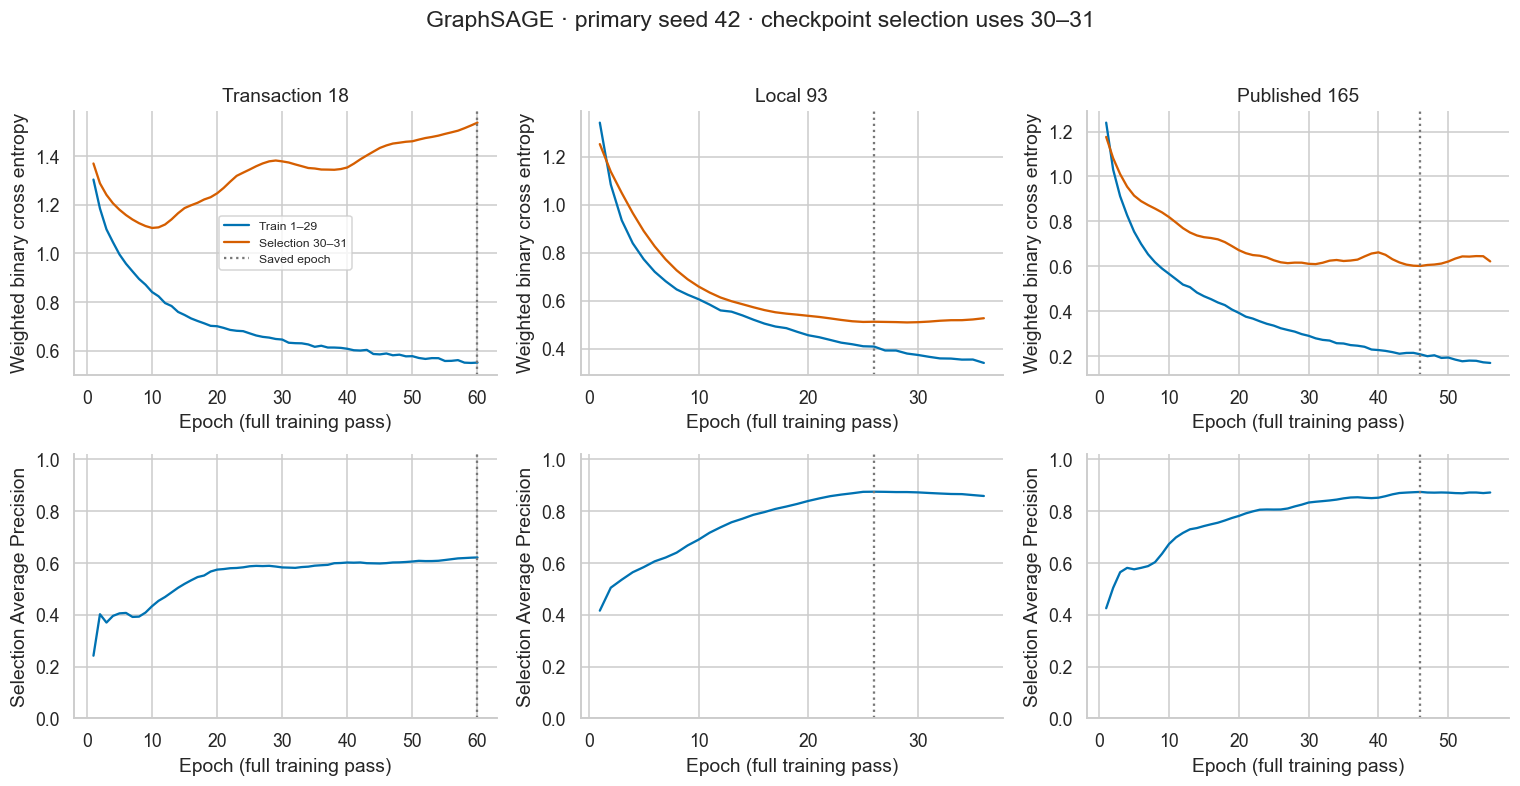

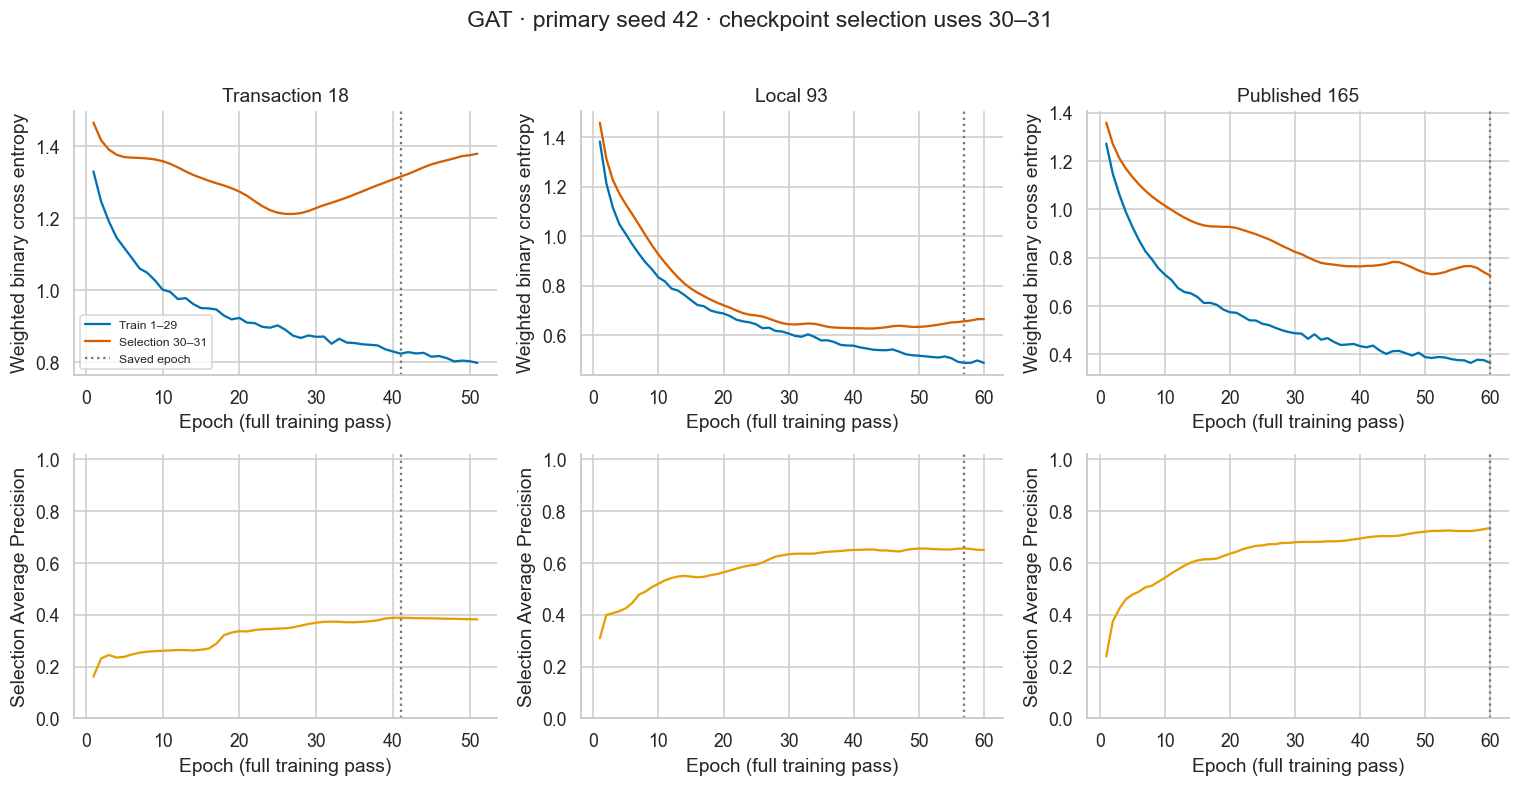

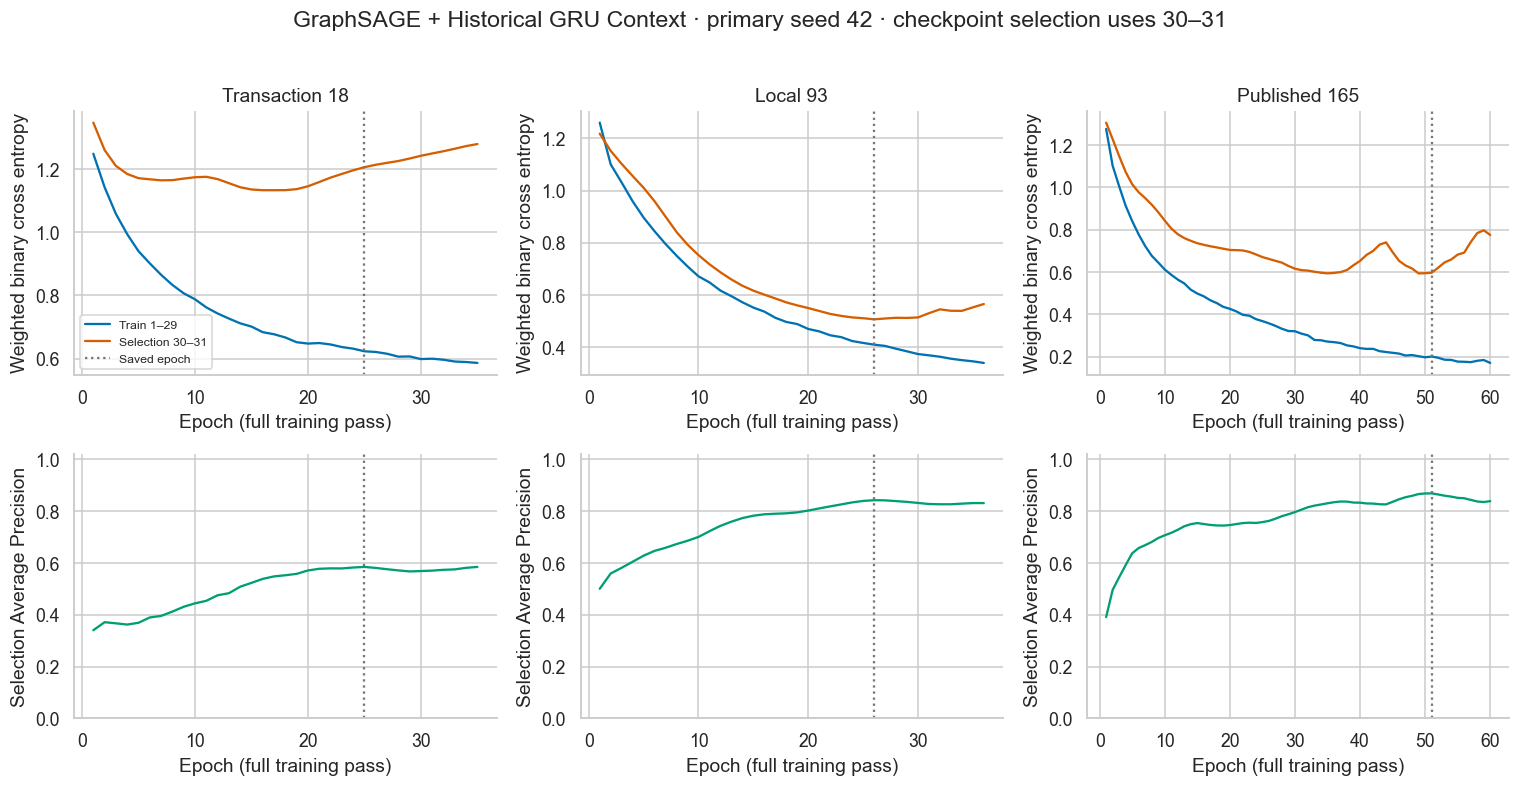

In [10]:
def primary_run(architecture, group):
    return next(run for run in selected_runs if run["architecture"] == architecture
                and run["feature_configuration"] == group and run["edge_mode"] == "original"
                and run["seed"] == PRIMARY_SEED)

def plot_learning_curves(architecture, filename):
    fig, axes = plt.subplots(2, 3, figsize=(14, 7))
    for column, group in enumerate(FEATURE_SETS):
        run = primary_run(architecture, group)
        history = pd.read_csv(RESULT_DIR / "histories" / f"{run['run_id']}.csv")
        axes[0, column].plot(history.epoch, history.training_loss, label="Train 1–29", color="#0072B2")
        axes[0, column].plot(history.epoch, history.selection_loss, label="Selection 30–31", color="#D55E00")
        axes[1, column].plot(history.epoch, history.selection_ap, color=COLORS[architecture])
        for row in [0, 1]:
            axes[row, column].axvline(run["best_epoch"], color="#777777", linestyle=":", label="Saved epoch")
            axes[row, column].set_xlabel("Epoch (full training pass)")
        axes[0, column].set(title=GROUP_NAMES[group], ylabel="Weighted binary cross entropy")
        axes[1, column].set(ylabel="Selection Average Precision", ylim=(0, 1.02))
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(f"{NAMES[architecture]} · primary seed {PRIMARY_SEED} · checkpoint selection uses 30–31", y=1.02)
    save_figure(fig, filename)

plot_learning_curves("graphsage", "stage3_01_graphsage_learning")
plot_learning_curves("gat", "stage3_02_gat_learning")
plot_learning_curves("sage_gru", "stage3_03_temporal_learning")

## 11. Matched assessment AP and PR curves

Bars summarize all predefined main seeds on step 34. Error bars are one seed SD (not confidence intervals); QUICK_RUN cannot estimate seed variation. The LightGBM reference has one recorded baseline seed. PR curves use the fixed primary seed 42 for each neural model and exactly the matched labeled candidates.

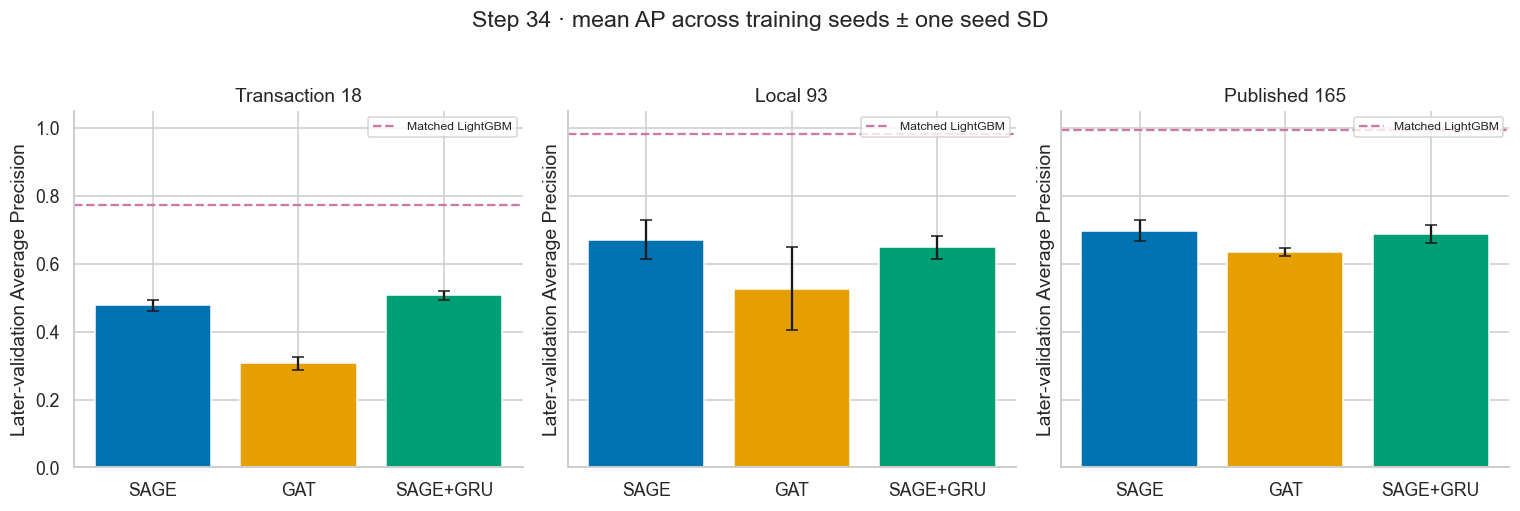

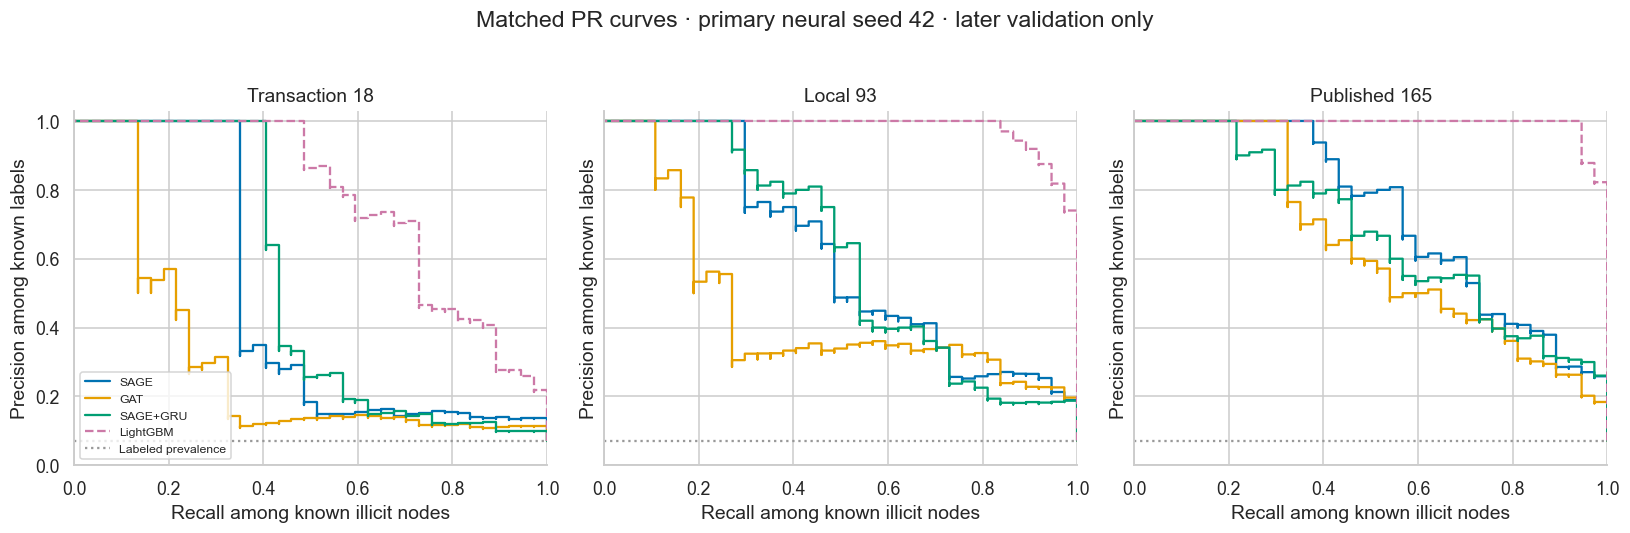

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True)
short_names = {"graphsage": "SAGE", "gat": "GAT", "sage_gru": "SAGE+GRU"}
for ax, group in zip(axes, FEATURE_SETS):
    view = aggregate.loc[aggregate.feature_configuration == group].set_index("architecture").loc[ARCHITECTURES]
    ax.bar(range(3), view.ap_mean, yerr=view.ap_sd.fillna(0), capsize=4,
           color=[COLORS[name] for name in ARCHITECTURES])
    baseline_ap = baseline_view.loc[baseline_view.feature_configuration == group, "average_precision"].item()
    ax.axhline(baseline_ap, color=COLORS["lightgbm"], linestyle="--", label="Matched LightGBM")
    ax.set(title=GROUP_NAMES[group], ylabel="Later-validation Average Precision", xticks=range(3),
           xticklabels=[short_names[name] for name in ARCHITECTURES], ylim=(0, 1.05))
    ax.legend(fontsize=8)
fig.suptitle("Step 34 · mean AP across training seeds ± one seed SD", y=1.03)
save_figure(fig, "stage3_04_architecture_ap")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.7), sharey=True)
for ax, group in zip(axes, FEATURE_SETS):
    for architecture in ARCHITECTURES:
        model_id = f"{architecture}__{group}__original__seed{PRIMARY_SEED}__raw"
        frame = audit_predictions.loc[audit_predictions.model_name == model_id]
        precision, recall, _ = precision_recall_curve(frame.true_label, frame.predicted_probability)
        ax.step(recall, precision, where="post", color=COLORS[architecture], label=short_names[architecture])
    baseline_name = baseline_view.loc[baseline_view.feature_configuration == group, "model_name"].item()
    frame = baseline_audit.loc[baseline_audit.model_name == baseline_name]
    precision, recall, _ = precision_recall_curve(frame.true_label, frame.predicted_probability)
    ax.step(recall, precision, where="post", color=COLORS["lightgbm"], linestyle="--", label="LightGBM")
    ax.axhline(audit_rows.target.mean(), color="#999999", linestyle=":", label="Labeled prevalence")
    ax.set(title=GROUP_NAMES[group], xlabel="Recall among known illicit nodes", ylabel="Precision among known labels", xlim=(0, 1), ylim=(0, 1.03))
axes[0].legend(fontsize=8, loc="lower left")
fig.suptitle("Matched PR curves · primary neural seed 42 · later validation only", y=1.03)
save_figure(fig, "stage3_05_matched_pr_curves")

**Interpretation:** The 18-feature comparison asks about graph learning with fewer future-prone inputs; it still cannot establish clean real-time prediction. Matching or exceeding a published-feature benchmark on this single period is not evidence of independent entity generalization. Changes across feature groups cannot identify the causal contribution of leakage or topology.

## 12. Quality, cost, graph controls and temporal context

Neural wall times below include each selected fit's stopping/selection passes and backend overhead. They are not controlled hardware benchmarks or totals for all candidate/seed fits. The temporal model has a larger classifier/context mechanism and processes history; a static-versus-temporal difference does not isolate a causal effect of memory.

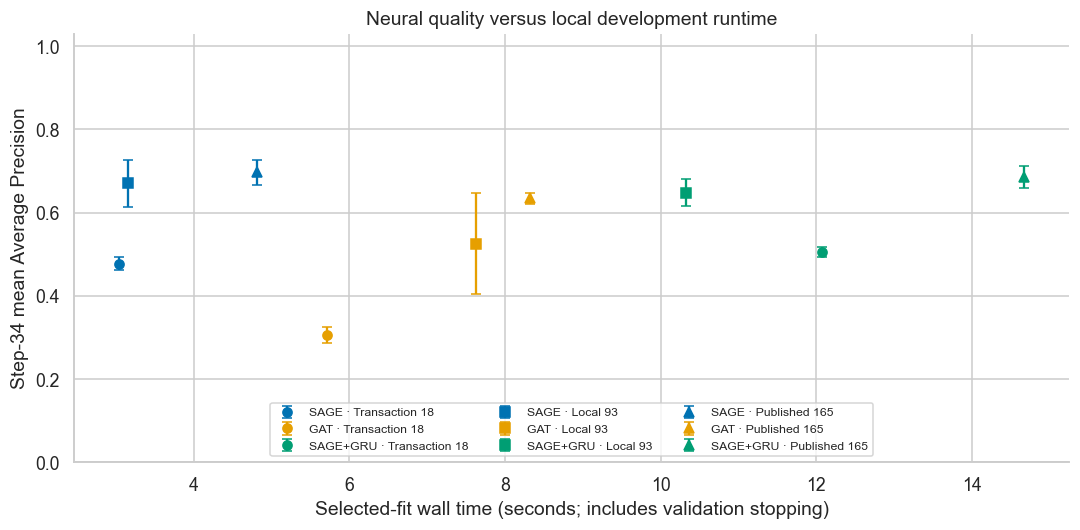

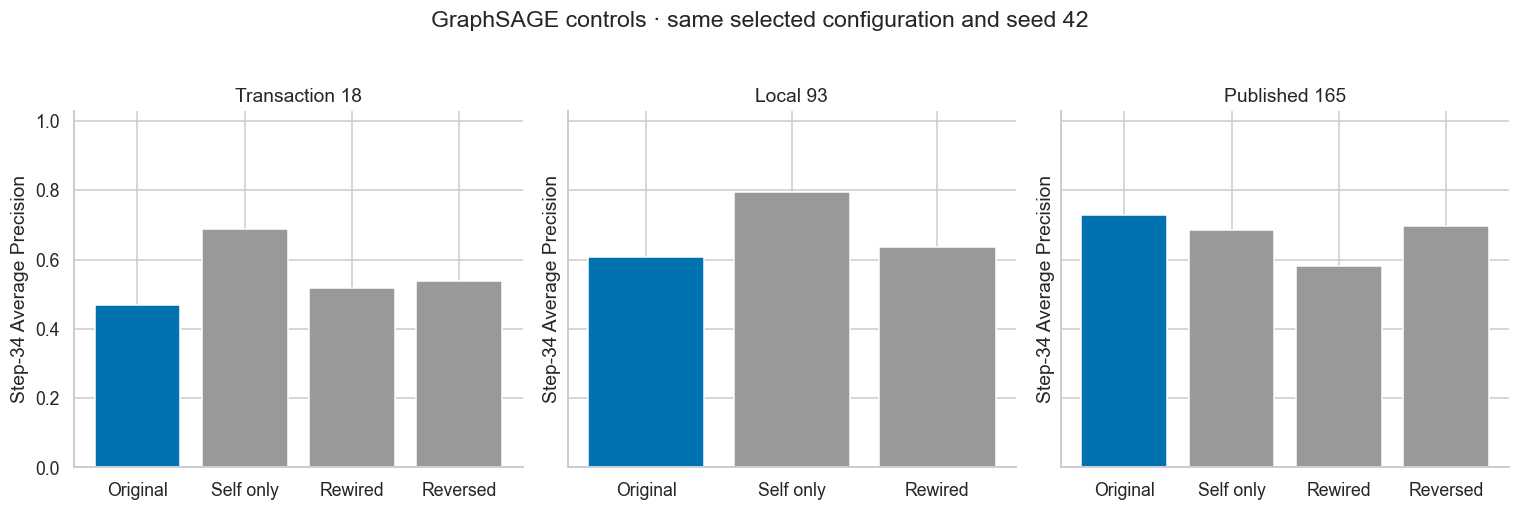

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))
markers = {"conservative18": "o", "local93": "s", "published165": "^"}
for row in aggregate.itertuples():
    ax.errorbar(row.fit_seconds_mean, row.ap_mean, yerr=0 if pd.isna(row.ap_sd) else row.ap_sd,
                fmt=markers[row.feature_configuration], color=COLORS[row.architecture], capsize=3,
                label=f"{short_names[row.architecture]} · {GROUP_NAMES[row.feature_configuration]}")
ax.set(xlabel="Selected-fit wall time (seconds; includes validation stopping)", ylabel="Step-34 mean Average Precision",
       title="Neural quality versus local development runtime", ylim=(0, 1.03))
ax.legend(fontsize=8, ncol=3, loc="lower center")
save_figure(fig, "stage3_06_quality_runtime")

control_view = metrics_table.loc[(metrics_table.architecture == "graphsage")
    & (metrics_table.seed == PRIMARY_SEED) & (metrics_table.calibration == "raw")].copy()
control_view.to_csv(RESULT_DIR / "graph_control_comparison.csv", index=False)
edge_labels = {"original": "Original", "self_only": "Self only", "rewired": "Rewired", "reversed": "Reversed"}
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True)
for ax, group in zip(axes, FEATURE_SETS):
    view = control_view.loc[control_view.feature_configuration == group]
    order = [name for name in edge_labels if name in set(view.edge_mode)]
    view = view.set_index("edge_mode").loc[order]
    ax.bar(range(len(view)), view.average_precision,
           color=["#0072B2" if name == "original" else "#999999" for name in order])
    ax.set(title=GROUP_NAMES[group], xticks=range(len(view)), xticklabels=[edge_labels[name] for name in order],
           ylabel="Step-34 Average Precision", ylim=(0, 1.03))
fig.suptitle("GraphSAGE controls · same selected configuration and seed 42", y=1.03)
save_figure(fig, "stage3_07_graph_controls")

**Interpretation:** These single-seed controls ask whether the chosen learner relies on the released adjacency under a fixed input setting. Degree changes and one random draw limit the rewiring interpretation. Strong self-only performance would indicate that this pipeline can rely on node inputs; it would not prove that graph information is unimportant in other models or data.

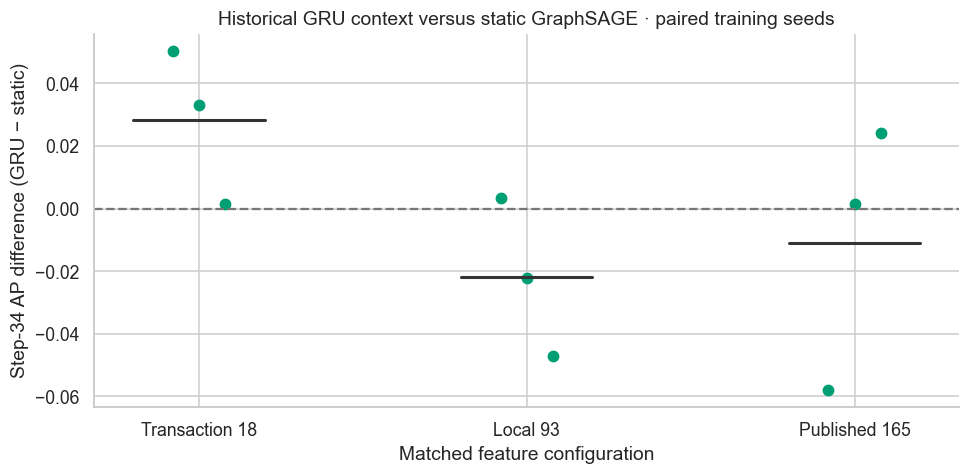

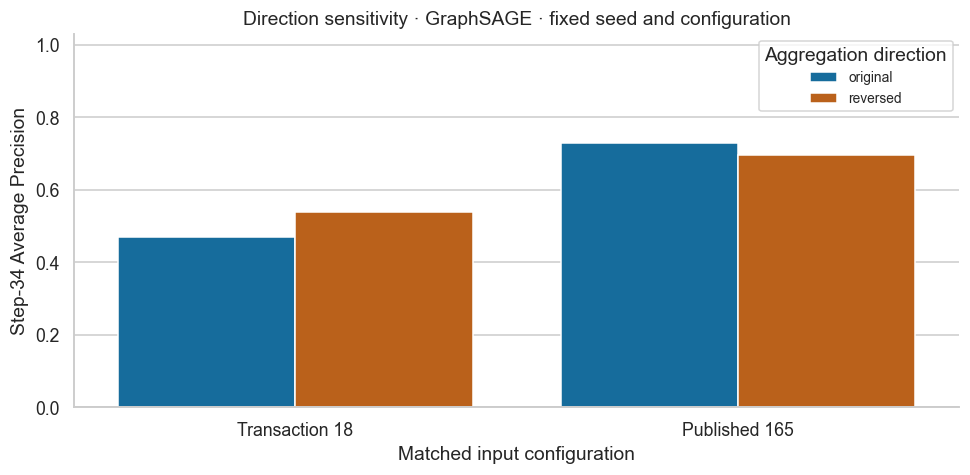

In [13]:
paired = main_raw.pivot(index=["feature_configuration", "seed"], columns="architecture", values="average_precision").reset_index()
paired["temporal_minus_static_ap"] = paired.sage_gru - paired.graphsage
paired.to_csv(RESULT_DIR / "paired_temporal_comparison.csv", index=False)
fig, ax = plt.subplots(figsize=(9, 4.5))
for position, group in enumerate(FEATURE_SETS):
    values = paired.loc[paired.feature_configuration == group, "temporal_minus_static_ap"].to_numpy()
    offsets = np.linspace(-0.08, 0.08, len(values))
    ax.scatter(position + offsets, values, color=COLORS["sage_gru"], s=45)
    ax.plot([position - .2, position + .2], [values.mean()] * 2, color="#333333", linewidth=2)
ax.axhline(0, color="#777777", linestyle="--")
ax.set(title="Historical GRU context versus static GraphSAGE · paired training seeds",
       xlabel="Matched feature configuration", ylabel="Step-34 AP difference (GRU − static)",
       xticks=range(3), xticklabels=[GROUP_NAMES[group] for group in FEATURE_SETS])
save_figure(fig, "stage3_08_temporal_difference")

fig, ax = plt.subplots(figsize=(9, 4.5))
direction = control_view.loc[control_view.feature_configuration.isin(["conservative18", "published165"])
                             & control_view.edge_mode.isin(["original", "reversed"])]
sns.barplot(data=direction, x="feature_configuration", y="average_precision", hue="edge_mode",
            errorbar=None, palette={"original": "#0072B2", "reversed": "#D55E00"}, ax=ax)
ax.set(title="Direction sensitivity · GraphSAGE · fixed seed and configuration",
       xlabel="Matched input configuration", ylabel="Step-34 Average Precision", ylim=(0, 1.03))
ax.set_xticks(range(2), ["Transaction 18", "Published 165"])
ax.legend(title="Aggregation direction", fontsize=9)
save_figure(fig, "stage3_09_direction_sensitivity")

**Interpretation:** The paired differences retain all predefined seeds, including unfavorable temporal runs. Shared address histories and label selection can create stable temporal patterns without proving operational forecasting value. Reversal changes which within-snapshot neighbors send messages and is reported separately from the default flow direction. In this linear-head version, the historical term is a shared logit offset, so AP differences between separately trained models must not be attributed directly to context-based node reranking.

## 13. Reproducible PCA view of model embeddings

Use the important 18-feature setting and seed 42. For each model, PCA is fitted on the same seeded uniform sample of training nodes, then applied to a fixed step-34 sample stratified by published label availability (up to 150 licit, 150 illicit, 150 unknown). Every illicit node is retained if fewer than 150 exist. This sampling overrepresents labeled/illicit nodes and is not population-representative.

Each architecture has its own training-fitted PCA axes. Two-dimensional separation or overlap **does not establish classification quality**. Neither embeddings nor the projection are used for hyperparameter selection or predictive fitting.

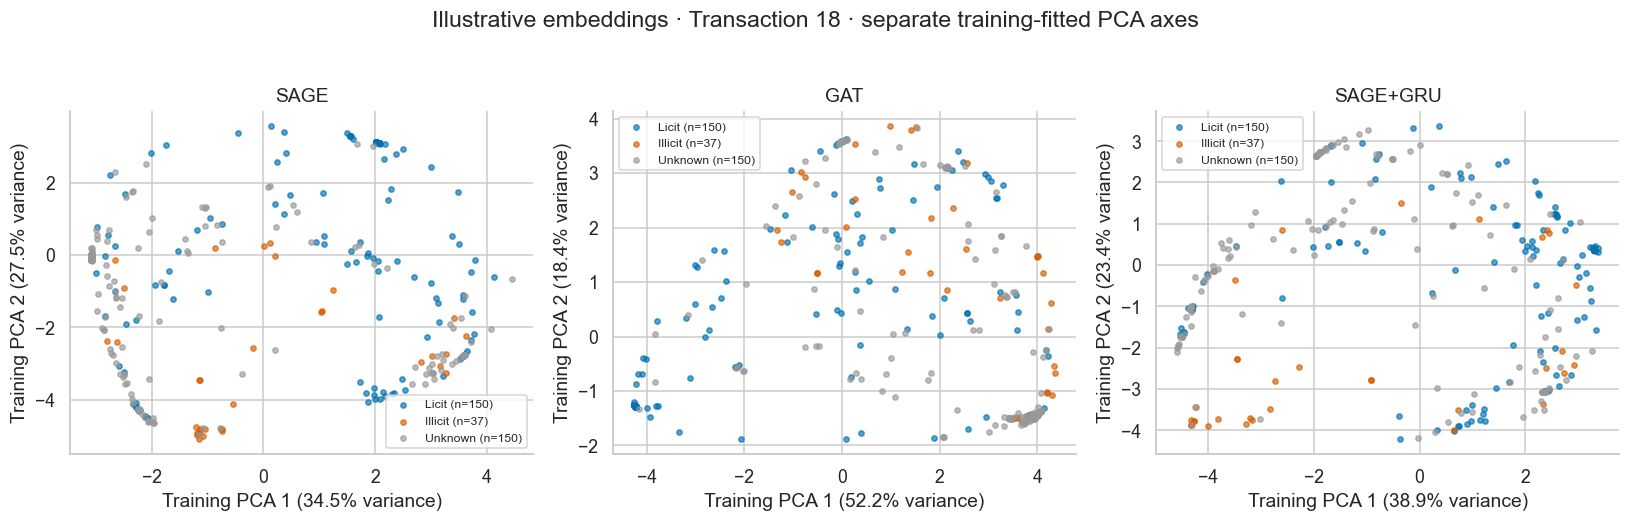

In [14]:
group = "conservative18"
graphs_cpu = original_graphs[group]
training_indices = np.concatenate([graphs_cpu[step].node_index.numpy() for step in range(1, 30)])
rng = np.random.default_rng(PRIMARY_SEED)
training_sample_positions = np.sort(rng.choice(len(training_indices), size=min(PCA_TRAIN_SAMPLE, len(training_indices)), replace=False))
audit_all = nodes.iloc[graphs_cpu[34].node_index.numpy()].copy()
audit_all["display_class"] = audit_all.target.map({0: "Licit", 1: "Illicit"}).fillna("Unknown")
sampled = pd.concat([frame.sample(n=min(len(frame), EMBEDDING_SAMPLE_PER_CLASS), random_state=PRIMARY_SEED)
                     for _, frame in audit_all.groupby("display_class", sort=True)])
audit_lookup = {int(index): position for position, index in enumerate(graphs_cpu[34].node_index.numpy())}
sample_positions = np.array([audit_lookup[int(index)] for index in sampled.node_index])
class_colors = {"Licit": "#0072B2", "Illicit": "#D55E00", "Unknown": "#999999"}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
projection_records = []
for ax, architecture in zip(axes, ARCHITECTURES):
    run = primary_run(architecture, group)
    saved = torch.load(MODEL_DIR / f"{run['run_id']}.pt", map_location="cpu", weights_only=True)
    model = GraphRiskModel(**saved["model_config"])
    model.load_state_dict(saved["state_dict"])
    model.to(run["device"])
    graphs_device = {step: graph.clone().to(run["device"]) for step, graph in graphs_cpu.items()}
    embedded = infer_snapshots(model, graphs_device, list(range(1, 30)) + [34], embeddings=True)
    training_embeddings = np.concatenate([embedded[step]["embeddings"] for step in range(1, 30)])
    pca = PCA(n_components=2, svd_solver="full")
    pca.fit(training_embeddings[training_sample_positions])
    coordinates = pca.transform(embedded[34]["embeddings"][sample_positions])
    for class_name, color in class_colors.items():
        mask = sampled.display_class.to_numpy() == class_name
        ax.scatter(coordinates[mask, 0], coordinates[mask, 1], s=12, alpha=.65, color=color,
                   label=f"{class_name} (n={mask.sum()})")
    ax.set(title=short_names[architecture], xlabel=f"Training PCA 1 ({pca.explained_variance_ratio_[0]:.1%} variance)",
           ylabel=f"Training PCA 2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
    ax.legend(fontsize=8)
    projection_records.append({"architecture": architecture, "feature_configuration": group,
        "pca_fit_nodes": len(training_sample_positions), "displayed_nodes": len(sampled),
        "pc1_training_variance": float(pca.explained_variance_ratio_[0]),
        "pc2_training_variance": float(pca.explained_variance_ratio_[1])})
fig.suptitle("Illustrative embeddings · Transaction 18 · separate training-fitted PCA axes", y=1.03)
save_figure(fig, "stage3_10_embedding_pca")
pd.DataFrame(projection_records).to_csv(RESULT_DIR / "embedding_projection_summary.csv", index=False)

## 14. Save the development record and report genuine behavior

All selected runs, seeds, histories, runtime breakdowns, early-stop epochs, hardware choices, checkpoints and operating rules are retained. Neural seed variability is reported independently of the single recorded LightGBM reference. No final-test ranking or complete research freeze is created here; Final-test evaluation was conducted subsequently in Stage 4.

In [15]:
versions = {name: importlib.metadata.version(name) for name in ["torch", "torch-geometric", "numpy", "pandas", "scikit-learn", "scipy", "matplotlib", "seaborn", "joblib"]}
run_config = {"stage": 3, "run_mode": RUN_MODE, "exploratory": QUICK_RUN, "seeds": SEEDS,
    "primary_seed": PRIMARY_SEED, "feature_sets": FEATURE_SETS, "group_helper_keys": GROUP_KEYS,
    "architecture_settings": {"graph_layers": 2, "hidden_dim": HIDDEN_DIM, "context_dim": CONTEXT_DIM,
                              "dropout": DROPOUT, "gat_heads_first_layer": GAT_HEADS, "gat_heads_second_layer": 1,
                              "attention_dropout": ATTENTION_DROPOUT, "normalization": "per-node LayerNorm"},
    "learning_rates": LEARNING_RATES, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
    "min_ap_improvement": MIN_AP_IMPROVEMENT, "weight_decay": WEIGHT_DECAY, "gradient_clip": GRADIENT_CLIP,
    "positive_weight": positive_weight, "optimizer": "Adam", "training_steps": [1, 29],
    "selection_steps": [30, 31], "calibration_steps": [32, 33], "assessment_steps": [34],
    "target_fpr": TARGET_FPR, "review_k_per_snapshot": REVIEW_K, "rewire_seed": REWIRE_SEED,
    "rewiring": "uniform unique directed within-snapshot edges; same budget, degrees not preserved",
    "temporal_context": "mean of all observed-node GraphSAGE embeddings; GRU state uses strictly earlier summaries",
    "temporal_gradients": "full backpropagation through training snapshots 1–29; no label inputs",
    "python": platform.python_version(), "architecture": platform.machine(), "versions": versions,
    "cpu_threads": CPU_THREADS, "device_policy": DEVICE_POLICY, "chosen_backends": BACKENDS,
    "raw_sha256": raw_hashes, "address_history_lightgbm_gain_share": address_gain_share,
    "selected_runs": selected_runs, "total_fit_candidates": len(fit_records),
    "main_models": int((selected_table.experiment == "main").sum()), "control_models": int((selected_table.experiment == "control").sum()),
    "raw_prediction_rows": len(raw_predictions), "calibrated_prediction_rows": int(audit_predictions.model_name.str.endswith("__platt").sum()),
    "population_checks_passed": True, "checkpoint_checks_passed": len(checkpoint_checks),
    "pca_training_sample": PCA_TRAIN_SAMPLE, "embedding_sample_per_class_cap": EMBEDDING_SAMPLE_PER_CLASS,
    "figures": figure_names, "seconds": round(time.perf_counter() - started_at, 3),
    "maximum_constructed_snapshot": 34, "final_test_predictions_computed": False, "final_test_rankings_computed": False,
    "feature_provenance": "none of the feature groups is certified leakage-free"}
(RESULT_DIR / "selected_configurations.json").write_text(json.dumps(run_config, indent=2, allow_nan=False) + "\n")
lines = [f"- **{len(fit_records)} fits**, **{run_config['main_models']} selected main models**, **{run_config['control_models']} one-seed controls**.",
         f"- All three architectures compared on matched 18/93/165 inputs; no unknown target or future graph enters fitting.",
         f"- Common labeled step-34 population: **{len(audit_rows)} transactions, {int(audit_rows.target.sum())} illicit**.",
         f"- Saved **{len(figure_names)} new figures**, local prediction files, histories and reload-checked checkpoints."]
for group in FEATURE_SETS:
    view = aggregate.loc[aggregate.feature_configuration == group]
    values = ", ".join(f"{short_names[row.architecture]} AP {row.ap_mean:.4f}" + (f" ± {row.ap_sd:.4f}" if row.seeds > 1 else " (one exploratory seed)") for row in view.itertuples())
    baseline_ap = baseline_view.loc[baseline_view.feature_configuration == group, "average_precision"].item()
    lines.append(f"- **{GROUP_NAMES[group]}**: {values}; matched LightGBM AP **{baseline_ap:.4f}**.")
lines.append("- These are limited later-validation observations, not evidence of causal graph value, leakage freedom or final-test superiority.")
if QUICK_RUN:
    lines.insert(0, "**QUICK_RUN — exploratory only.**")
display(Markdown("\n".join(lines)))
print(f"Stage 3 runtime: {run_config['seconds']:.1f} seconds.")

- **44 fits**, **27 selected main models**, **8 one-seed controls**.
- All three architectures compared on matched 18/93/165 inputs; no unknown target or future graph enters fitting.
- Common labeled step-34 population: **515 transactions, 37 illicit**.
- Saved **10 new figures**, local prediction files, histories and reload-checked checkpoints.
- **Transaction 18**: SAGE AP 0.4776 ± 0.0160, GAT AP 0.3063 ± 0.0183, SAGE+GRU AP 0.5061 ± 0.0125; matched LightGBM AP **0.7725**.
- **Local 93**: SAGE AP 0.6704 ± 0.0573, GAT AP 0.5259 ± 0.1214, SAGE+GRU AP 0.6484 ± 0.0335; matched LightGBM AP **0.9801**.
- **Published 165**: SAGE AP 0.6966 ± 0.0311, GAT AP 0.6342 ± 0.0124, SAGE+GRU AP 0.6858 ± 0.0265; matched LightGBM AP **0.9919**.
- These are limited later-validation observations, not evidence of causal graph value, leakage freedom or final-test superiority.

Stage 3 runtime: 337.1 seconds.


### References and interpretation limits

- [Stage 1 source audit](../reports/leakage_audit.md); [current research protocol](../reports/research_protocol.md); [Šafář et al. (2026)](https://doi.org/10.1016/j.fsidi.2026.302124).
- [PyG 2.7 GraphSAGE operator](https://pytorch-geometric.readthedocs.io/en/2.7.0/generated/torch_geometric.nn.conv.SAGEConv.html) and [GAT operator](https://pytorch-geometric.readthedocs.io/en/2.7.0/generated/torch_geometric.nn.conv.GATConv.html).
- [Original GraphSAGE paper](https://arxiv.org/abs/1706.02216) and [GAT paper](https://arxiv.org/abs/1710.10903).

The historical-GRU model is a modest snapshot-context extension, not a reproduction of a named temporal-graph paper or a claim of architectural novelty. The one-snapshot assessment, three training seeds, unequal parameter counts, one rewiring draw and source-feature contamination limit conclusions. Source reconstruction, entity-disjoint evaluation and broad robustness remain unresolved; they are not silently solved by this implementation.